# Импорты и настройки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style="whitegrid")

# Загрузка данных.

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# Размер, типы, пропуски.

In [3]:
print("Размер:", df.shape)
df.info()

Размер: (41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 

# Статистика по числовым и категориальным признакам.

In [4]:
df.describe().T
df.describe(include="object").T

C:\Windows\Temp\ipykernel_7476\464569667.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


# Пропуски и дубликаты в данных.

In [5]:
print("Пропуски:", df.isna().sum())
print("Дубликаты:", df.duplicated().sum())

Пропуски: age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
Дубликаты: 12


In [6]:
print("Полных дубликатов:", df.duplicated().sum())
dups = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))
dups.head(20)

Полных дубликатов: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


In [7]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(df.shape, "→", df_clean.shape)

(41188, 21) → (41176, 21)


# Баланс/дисбаланс классов.

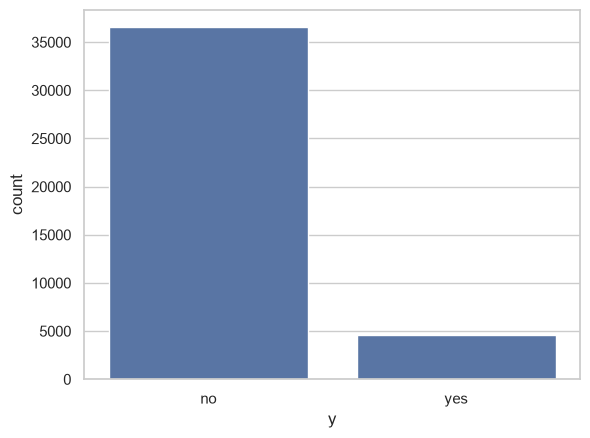

In [8]:
df["y"].value_counts()
df["y"].value_counts(normalize=True).round(3)
sns.countplot(data=df, x="y")
plt.show()

# Подготовка к анализу данных.

In [9]:
base_rate = (df["y"] == "yes").mean()
print(f"Базовая доля ответов yes: {base_rate:.3f}")
df["y_num"] = (df["y"] == "yes").astype(int)
months = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
df["month"] = pd.Categorical(df["month"], categories=months, ordered=True)

Базовая доля ответов yes: 0.113


# Анализ истории контактов.

## Обнаружение неявного пропуска в данных о количестве дней, прошедших с момента последнего контакта банка с клиентом.

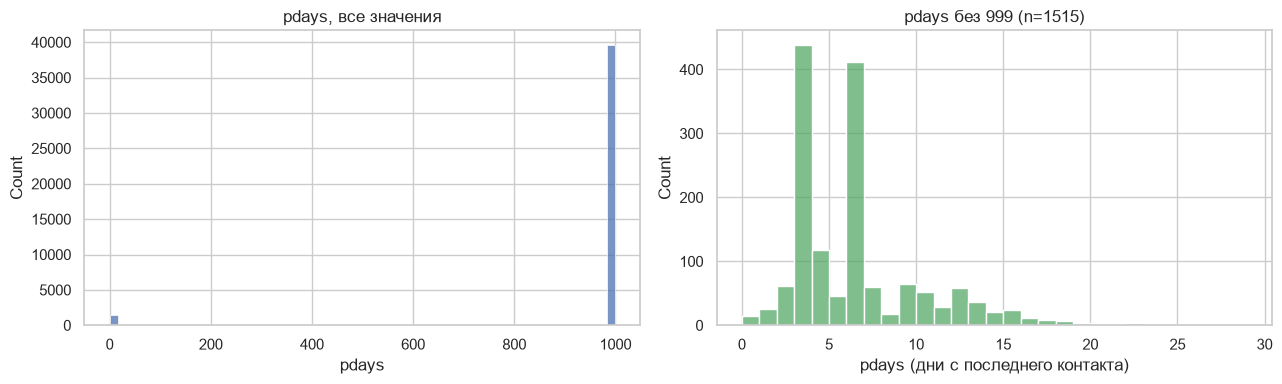

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# слева: всё как есть — 999 доминирует, реальные дни не видны
sns.histplot(df["pdays"], bins=60, ax=axes[0], color="C0")
axes[0].set_title("pdays, все значения")
axes[0].set_xlabel("pdays")

# справа: только те, где pdays != 999 — вот это и есть "настоящие" дни
real = df.loc[df["pdays"] != 999, "pdays"]
sns.histplot(real, bins=range(0, 30), ax=axes[1], color="C2")
axes[1].set_title(f"pdays без 999 (n={len(real)})")
axes[1].set_xlabel("pdays (дни с последнего контакта)")

plt.tight_layout(); plt.show()

## Обнаружение неявных пропусков в данных со значением unknown.

In [16]:
unk_counts = (df == "unknown").sum()
unk_counts = unk_counts[unk_counts > 0].sort_values(ascending=False)

implicit_na = pd.DataFrame({
    "column":        unk_counts.index,
    "count_unknown": unk_counts.values,
    "dtype":         [df[c].dtype for c in unk_counts.index],
}).reset_index(drop=True)

implicit_na

,column,count_unknown,dtype
0,default,8597,str
1,education,1731,str
2,housing,990,str
3,loan,990,str
4,job,330,str
5,marital,80,str


## Обработка данных о количестве дней, прошедших с момента последнего контакта банка с клиентом.

In [19]:
df["was_contacted_before"] = (df["pdays"] != 999).astype(int)
df["pdays_clean"] = df["pdays"].where(df["pdays"] != 999)

# Визуализации анализируемых данных.

In [23]:
df["pdays_bin"] = pd.cut(df["pdays_clean"], [-1, 0, 3, 7, 14, 30])
df["age_bin"] = pd.cut(df["age"], [17, 25, 35, 45, 55, 65, 100])
df["is_yes"] = (df["y"] == "yes").astype(int)

## Анализ истории контактов.

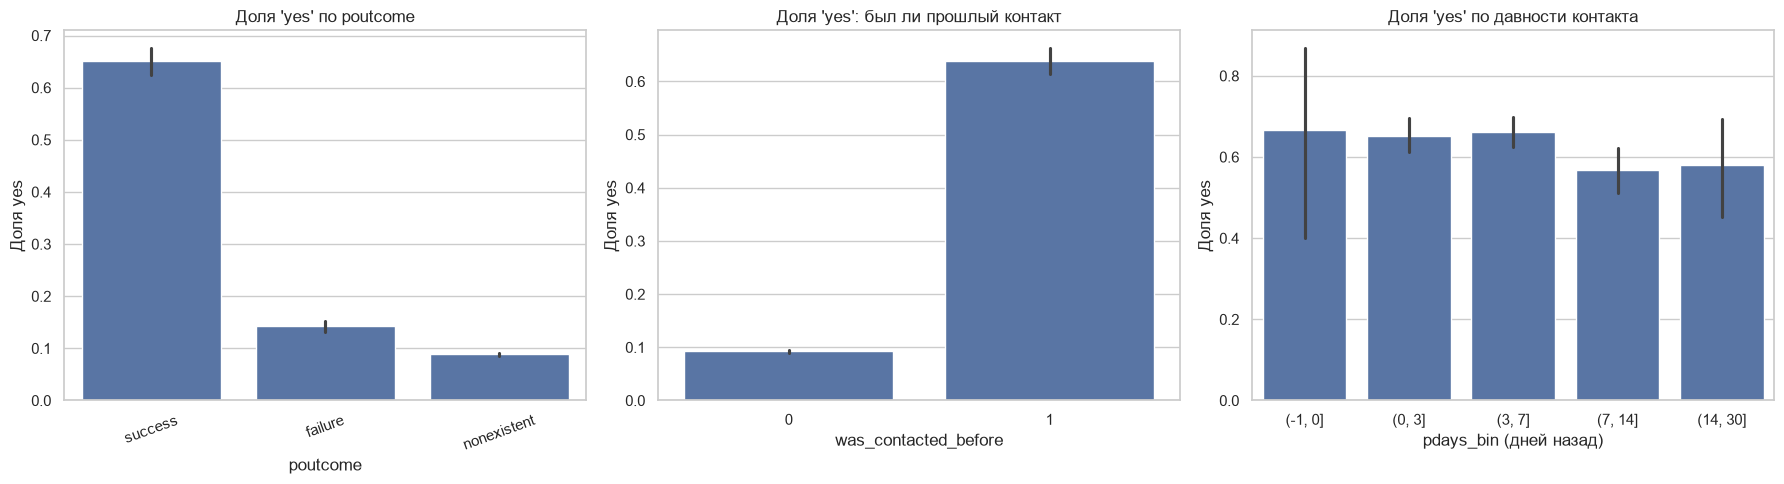

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=df, x="poutcome", y="is_yes",
    order=df.groupby("poutcome")["is_yes"].mean().sort_values(ascending=False).index,
    ax=axes[0]
)
axes[0].set_title("Доля 'yes' по poutcome")
axes[0].set_ylabel("Доля yes")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="was_contacted_before", y="is_yes", ax=axes[1])
axes[1].set_title("Доля 'yes': был ли прошлый контакт")
axes[1].set_xlabel("was_contacted_before")
axes[1].set_ylabel("Доля yes")

sns.barplot(data=df, x="pdays_bin", y="is_yes", ax=axes[2])
axes[2].set_title("Доля 'yes' по давности контакта")
axes[2].set_xlabel("pdays_bin (дней назад)")
axes[2].set_ylabel("Доля yes")

plt.tight_layout()
plt.show()